In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import r2_score, root_mean_squared_error
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from xgboost import XGBRegressor

In [2]:
FILE_PATH = Path('Housing.csv')
data = pd.read_csv(FILE_PATH)

In [3]:
data.head()

,rownames,price,lotsize,bedrooms,bathrms,stories,driveway,recroom,fullbase,gashw,airco,garagepl,prefarea
0,1,42000,5850.0,3,1,2,yes,no,yes,no,no,1.0,no
1,2,38500,4000.0,2,1,1,yes,no,no,no,no,0.0,no
2,3,49500,3060.0,3,1,1,yes,no,no,no,no,0.0,no
3,4,60500,6650.0,3,1,2,yes,yes,no,no,no,0.0,no
4,5,61000,6360.0,2,1,1,yes,no,no,no,no,0.0,no


In [4]:
data.dtypes

rownames      int64
price         int64
lotsize     float64
bedrooms      int64
bathrms       int64
stories       int64
driveway        str
recroom         str
fullbase        str
gashw           str
airco           str
garagepl    float64
prefarea        str
dtype: object

In [5]:
data.shape

(546, 13)

In [6]:
data.isna().sum()

rownames    0
price       0
lotsize     5
bedrooms    0
bathrms     0
stories     0
driveway    2
recroom     4
fullbase    0
gashw       2
airco       7
garagepl    2
prefarea    2
dtype: int64

In [7]:
data.describe()

,rownames,price,lotsize,bedrooms,bathrms,stories,garagepl
count,546.000000,546.000000,541.000000,546.000000,546.000000,546.000000,544.000000
mean,273.500000,68121.597070,5160.611830,2.965201,1.285714,1.807692,0.694853
std,157.760895,26702.670926,2175.141222,0.737388,0.502158,0.868203,0.861864
min,1.000000,25000.000000,1650.000000,1.000000,1.000000,1.000000,0.000000
25%,137.250000,49125.000000,3584.000000,2.000000,1.000000,1.000000,0.000000
50%,273.500000,62000.000000,4600.000000,3.000000,1.000000,2.000000,0.000000
75%,409.750000,82000.000000,6360.000000,3.000000,2.000000,2.000000,1.000000
max,546.000000,190000.000000,16200.000000,6.000000,4.000000,4.000000,3.000000


In [8]:
target_col = 'price'
X = data.drop(target_col, axis=1)
y = data[target_col]

X, y

(     rownames  lotsize  bedrooms  bathrms  stories driveway recroom fullbase  \
 0           1   5850.0         3        1        2      yes      no      yes   
 1           2   4000.0         2        1        1      yes      no       no   
 2           3   3060.0         3        1        1      yes      no       no   
 3           4   6650.0         3        1        2      yes     yes       no   
 4           5   6360.0         2        1        1      yes      no       no   
 ..        ...      ...       ...      ...      ...      ...     ...      ...   
 541       542   4800.0         3        2        4      yes     yes       no   
 542       543   6000.0         3        2        4      yes      no       no   
 543       544   6000.0         3        2        4      yes     yes       no   
 544       545   6000.0         3        2        2      yes     yes       no   
 545       546   6000.0         3        1        2      yes      no       no   
 
     gashw airco  garagepl

In [9]:
numeric_features = X.select_dtypes(include='number').columns.to_list()
categorial_features = X.select_dtypes(exclude='number').columns.to_list()

print(f"""
Target column: {target_col}
Numeric features count: {len(numeric_features)}
Categorial features count: {len(categorial_features)}
""")


Target column: price
Numeric features count: 6
Categorial features count: 6



In [10]:
# Train - 64%, Valid - 16%, Test - 20%
X_tmp, X_test, y_tmp, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

X_train, X_valid, y_train, y_valid = train_test_split(X_tmp, y_tmp, test_size=0.2, random_state=42)

In [11]:
numeric_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='median')),
    ]
)
categorical_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore'))
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorial_features),
    ]
)

In [12]:
preprocessor.fit(X_train)
X_train_transformed = preprocessor.transform(X_train)
X_valid_transformed = preprocessor.transform(X_valid)
X_test_transformed = preprocessor.transform(X_test)

In [13]:
oh = preprocessor.named_transformers_['cat'].named_steps['onehot'] if categorial_features else None
num_names = numeric_features
cat_names = oh.get_feature_names_out(categorial_features).tolist() if oh is not None else []
feature_names = num_names + cat_names

In [14]:
feature_names

['rownames',
 'lotsize',
 'bedrooms',
 'bathrms',
 'stories',
 'garagepl',
 'driveway_no',
 'driveway_yes',
 'recroom_no',
 'recroom_yes',
 'fullbase_no',
 'fullbase_yes',
 'gashw_no',
 'gashw_yes',
 'airco_no',
 'airco_yes',
 'prefarea_no',
 'prefarea_yes']

In [16]:
print(f"""
X_train shape: {X_train_transformed.shape}
X_valid shape: {X_valid_transformed.shape}
X_test shape: {X_test_transformed.shape}
""")


X_train shape: (348, 18)
X_valid shape: (88, 18)
X_test shape: (110, 18)



# XGBoost - Оптимизированная и усовершенствованная версия алгоритма Gradient Boosting

Преимущества:
1. **Regularization (L1/L2)** - регуляризация помогает предотвратить переобучение модели (overfiting)
2. **Gradient and Hessian** - использует первую и вторую производные функции потерь (loss function)
3. **Missing values** - имеет встроенный механизм обработки пропущенных значений
4. **Parallel computation** - позволяет распараллеливать некоторые вычисления при построении деревьев
5. **Early stoping** - досрочная остановка обучения, если качество модели на валидационных данных перестает улучшатся

### Математическая логика XGBoost:
$$
\hat{y}^{(t)} = \hat{y}^{(t-1)} + \eta f_t(x)
$$

- $\hat{y}^{(t)}$ - новое итоговое предсказание модели на данном этапе
- $\hat{y}^{(t-1)}$ - предсказание модели на предыдущем этапе
- $\eta$ - **learning rate**, коэффициент скорости обучения, определяющий силу влияния новой корректировки на итоговое предсказание
- $f_t(x) $ - корректировка, которую вносит новое дерево

In [19]:
xgb = XGBRegressor(
    n_estimators=2000,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    tree_method="hist",
    random_state=42,
    n_jobs=-1,
    eval_metric="rmse",
    early_stopping_rounds=50
)
xgb.fit(X_train_transformed, y_train, eval_set=[(X_valid_transformed, y_valid)])

[0]	validation_0-rmse:26700.22286
[1]	validation_0-rmse:25992.75357
[2]	validation_0-rmse:25316.88183
[3]	validation_0-rmse:24497.58889
[4]	validation_0-rmse:23847.83375
[5]	validation_0-rmse:23232.67533
[6]	validation_0-rmse:22671.82525
[7]	validation_0-rmse:22194.17226
[8]	validation_0-rmse:21704.44277
[9]	validation_0-rmse:21280.59609
[10]	validation_0-rmse:20814.86790
[11]	validation_0-rmse:20258.36052
[12]	validation_0-rmse:19853.74866
[13]	validation_0-rmse:19696.90181
[14]	validation_0-rmse:19228.26321
[15]	validation_0-rmse:18980.49239
[16]	validation_0-rmse:18773.78920
[17]	validation_0-rmse:18556.80905
[18]	validation_0-rmse:18292.96545
[19]	validation_0-rmse:18004.06944
[20]	validation_0-rmse:17785.55965
[21]	validation_0-rmse:17660.21617
[22]	validation_0-rmse:17561.82923
[23]	validation_0-rmse:17316.86968
[24]	validation_0-rmse:17179.56758
[25]	validation_0-rmse:17032.82733
[26]	validation_0-rmse:16797.56183
[27]	validation_0-rmse:16650.20932
[28]	validation_0-rmse:16484.1

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,0.8
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",50
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'rmse'
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [20]:
def rmse(y_true, y_pred):
    return root_mean_squared_error(y_true, y_pred)

y_pred = xgb.predict(X_test_transformed)

print(f"""
RMSE (test): {rmse(y_test, y_pred):.3f}
R2 (test): {r2_score(y_test, y_pred):.3f})
Best iteration: {xgb.best_iteration}
"""
)


RMSE (test): 14390.280
R2 (test): 0.690)
Best iteration: 78



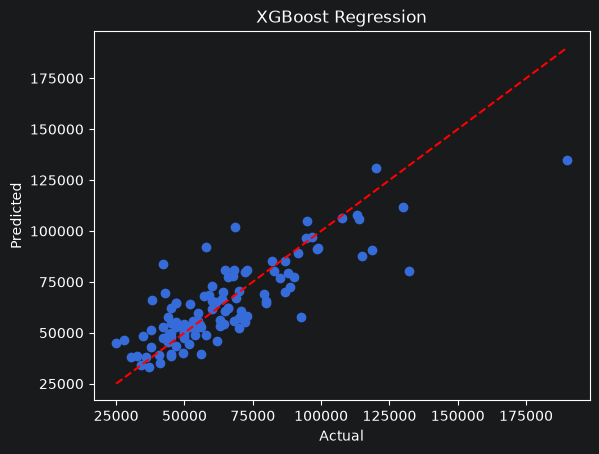

In [21]:
plt.figure()
plt.scatter(y_test, y_pred)
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.title('XGBoost Regression')
low = min(y_test.min(), y_pred.min())
high = max(y_test.max(), y_pred.max())
plt.plot([low, high], [low, high], 'r--')
plt.show()

In [22]:
importances = xgb.feature_importances_
imp_df = (pd.DataFrame(
    {
        'feature': feature_names if len(feature_names) == len(importances) else [f'feature_{i}' for i in range(len(importances))],
        'importance': importances
    }
).sort_values(by='importance', ascending=False).head(10)
)
imp_df

,feature,importance
3,bathrms,0.167334
14,airco_no,0.107649
1,lotsize,0.094046
11,fullbase_yes,0.075498
10,fullbase_no,0.062609
12,gashw_no,0.061566
5,garagepl,0.060346
13,gashw_yes,0.052261
4,stories,0.051547
16,prefarea_no,0.046125


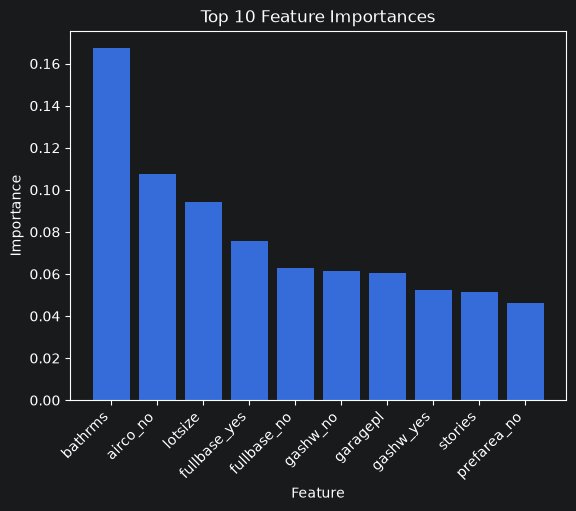

In [23]:
plt.figure()
plt.bar(imp_df['feature'], imp_df['importance'])
plt.title('Top 10 Feature Importances')
plt.xlabel('Feature')
plt.ylabel('Importance')
plt.xticks(rotation=45, ha='right')
plt.show()